# Student Scores Exploratory Data Analysis

Clean and explore `data/students.csv` with pandas, Matplotlib, and Seaborn. The last section checks whether a straight line can predict score.

In [1]:
from pathlib import Path
import warnings
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
%matplotlib inline

## Load and inspect the data

In [2]:
path = Path("../data/students.csv")
if not path.exists():
    path = Path("data/students.csv")

students = pd.read_csv(path)
print(students.shape)
display(students.head())
students.info()

(31, 10)


,student_id,name,city,department,subject,score,attendance,fee,joined,status
0,S01,Asha Rao,Pune,Computer Science,Python,88.0,92,45000.0,2023-07-12,Active
1,S02,Rahul Mehta,Mumbai,Computer Science,Python,76.0,85,45000.0,2023-07-15,Active
2,S03,Neha Shah,Delhi,Computer Science,Python,91.0,96,48000.0,2022-08-01,Alumni
3,S04,Vikram Singh,Bengaluru,Computer Science,Databases,67.0,70,45000.0,2024-01-10,Active
4,S05,Priya Nair,Pune,Computer Science,Databases,82.0,88,45000.0,2023-07-12,Active


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   student_id  31 non-null     object 
 1   name        31 non-null     object 
 2   city        28 non-null     object 
 3   department  31 non-null     object 
 4   subject     31 non-null     object 
 5   score       29 non-null     float64
 6   attendance  31 non-null     int64  
 7   fee         30 non-null     float64
 8   joined      31 non-null     object 
 9   status      31 non-null     object 
dtypes: float64(2), int64(1), object(7)
memory usage: 2.6+ KB


In [3]:
display(students.isna().sum().to_frame("missing"))
print("Duplicate rows:", students.duplicated().sum())
display(students.describe())

,missing
student_id,0
name,0
city,3
department,0
subject,0
score,2
attendance,0
fee,1
joined,0
status,0


Duplicate rows: 1


,score,attendance,fee
count,29.000000,31.000000,30.000000
mean,78.413793,83.387097,43333.333333
std,11.663488,10.886314,2454.177766
min,54.000000,60.000000,40000.000000
25%,71.000000,76.000000,42000.000000
50%,81.000000,86.000000,43000.000000
75%,88.000000,91.500000,45000.000000
max,95.000000,98.000000,50000.000000


## Clean the data

Drop the repeated row. Fill blank scores with the mean and the blank fee with the median. Fill blank cities with the most common city.

In [4]:
cleaned = students.drop_duplicates().copy()

cleaned["score"] = cleaned["score"].fillna(cleaned["score"].mean())
cleaned["fee"] = cleaned["fee"].fillna(cleaned["fee"].median())
cleaned["city"] = cleaned["city"].fillna(cleaned["city"].mode()[0])

print(cleaned.shape)
cleaned.head()

(30, 10)


,student_id,name,city,department,subject,score,attendance,fee,joined,status
0,S01,Asha Rao,Pune,Computer Science,Python,88.0,92,45000.0,2023-07-12,Active
1,S02,Rahul Mehta,Mumbai,Computer Science,Python,76.0,85,45000.0,2023-07-15,Active
2,S03,Neha Shah,Delhi,Computer Science,Python,91.0,96,48000.0,2022-08-01,Alumni
3,S04,Vikram Singh,Bengaluru,Computer Science,Databases,67.0,70,45000.0,2024-01-10,Active
4,S05,Priya Nair,Pune,Computer Science,Databases,82.0,88,45000.0,2023-07-12,Active


## Univariate exploration

Each histogram is the shape of one column. Scores and attendance both spread across the class. Fees sit in a few tight bands, one band per department.

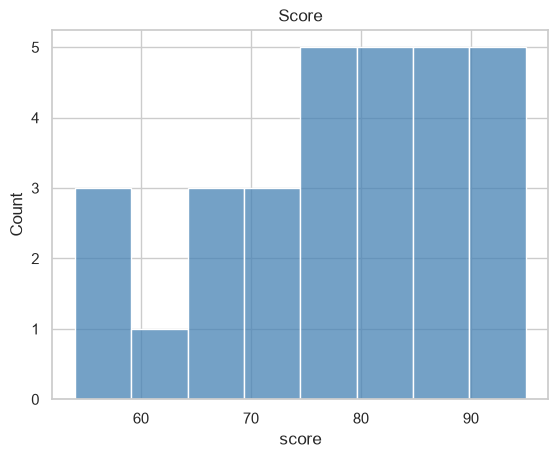

In [5]:
sns.histplot(data=cleaned, x="score", bins=8, color="steelblue")
plt.title("Score")
plt.show()

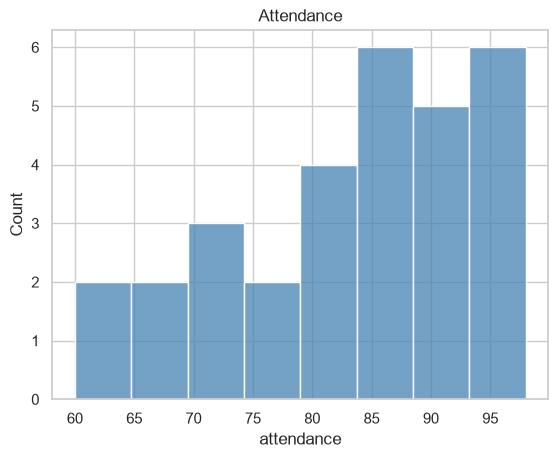

In [6]:
sns.histplot(data=cleaned, x="attendance", bins=8, color="steelblue")
plt.title("Attendance")
plt.show()

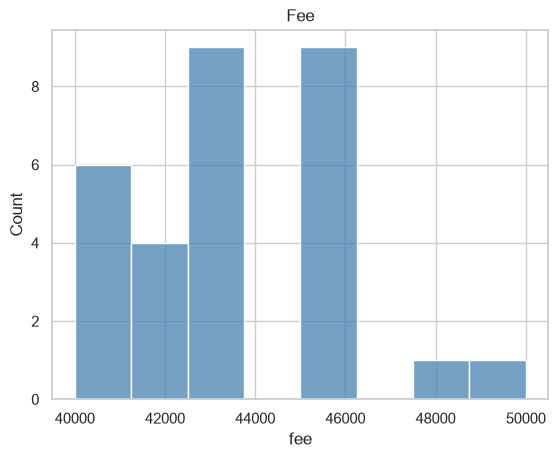

In [7]:
sns.histplot(data=cleaned, x="fee", bins=8, color="steelblue")
plt.title("Fee")
plt.show()

## Department comparisons

The three departments are the same size. Their average scores sit close together, so department alone does not separate high scores from low ones.

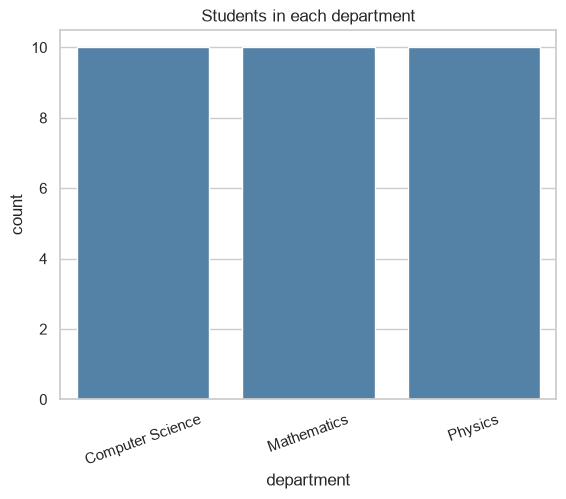

In [8]:
sns.countplot(data=cleaned, x="department", color="steelblue")
plt.title("Students in each department")
plt.xticks(rotation=20)
plt.show()

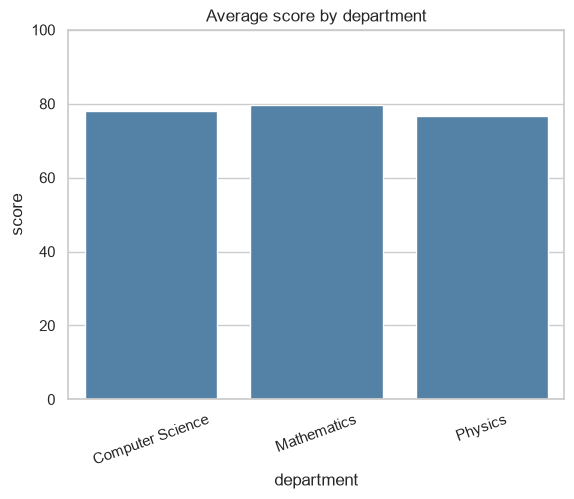

In [9]:
sns.barplot(data=cleaned, x="department", y="score", color="steelblue", errorbar=None)
plt.title("Average score by department")
plt.ylim(0, 100)
plt.xticks(rotation=20)
plt.show()

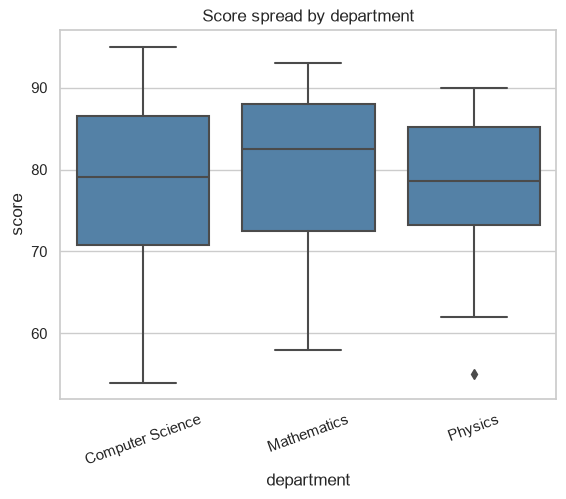

In [10]:
sns.boxplot(data=cleaned, x="department", y="score", color="steelblue")
plt.title("Score spread by department")
plt.xticks(rotation=20)
plt.show()

## Relationships

The heatmap is one number per pair. The line on each scatter is the straight-line fit.

Attendance and score rise together and stay close to the line. Fee slopes up only a little, and the points spread around that line.

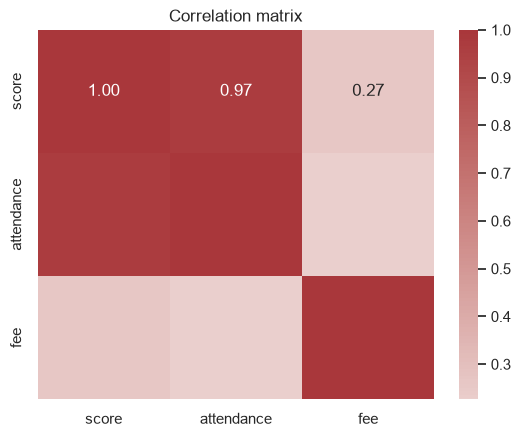

In [11]:
sns.heatmap(cleaned[["score", "attendance", "fee"]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation matrix")
plt.show()

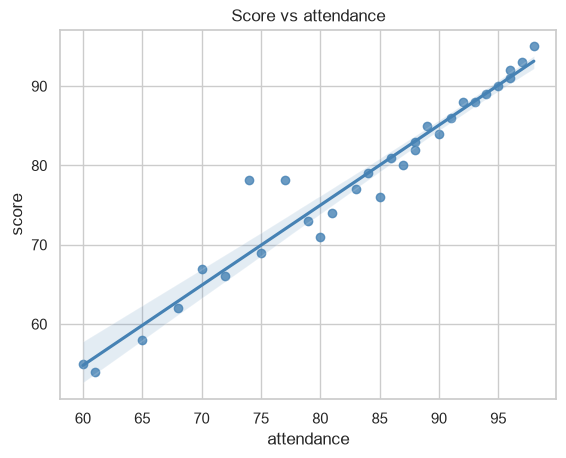

In [12]:
sns.regplot(data=cleaned, x="attendance", y="score", color="steelblue")
plt.title("Score vs attendance")
plt.show()

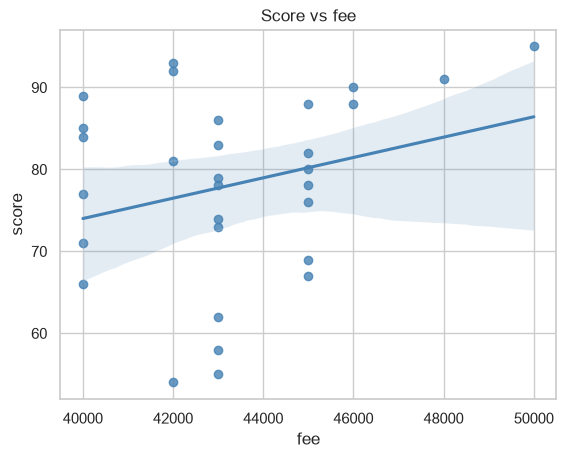

In [13]:
sns.regplot(data=cleaned, x="fee", y="score", color="steelblue")
plt.title("Score vs fee")
plt.show()

## Linear regression

The attendance chart is a straight line, so score can be predicted from attendance. The model below is that same line. Fee is left out because its chart is too scattered for a useful line.

In [14]:
model = LinearRegression().fit(cleaned[["attendance"]], cleaned["score"])
print(f"score = {model.intercept_:.1f} + {model.coef_[0]:.2f} * attendance")
print(f"R-squared: {model.score(cleaned[['attendance']], cleaned['score']):.2f}")

score = -5.8 + 1.01 * attendance
R-squared: 0.95


## Insights

- The repeated student row is removed, and the blank scores, fee, and cities are filled, so all 30 students stay in the charts.
- Each department has 10 students, and the average scores sit near each other, around the high 70s.
- A regression is possible. Score against attendance is a straight line (correlation about 0.98), and the fitted line explains almost all of the variation in score.
- Fee is a weak upward slope (correlation about 0.27). It does not give a second line worth fitting.